# CƠ SỞ PHÂN TÍCH DỮ LIỆU LỚN DÙNG PYSPARK

## Notebook thực hành
Notebook này đi cùng handout Word. Đặt notebook ở thư mục gốc của bộ tài liệu, sao cho dữ liệu nằm trong `Datasets/`.

NGUYỄN THỊ CHINH - 33241026114

> **Lưu ý:** Nếu máy chưa cài PySpark, có thể chạy ô cài đặt bên dưới một lần. Trên Google Colab, thường cần cài `pyspark`.

In [ ]:
# Bỏ dấu # nếu cần cài đặt
#!pip install -q pyspark

## 0. Khởi tạo môi trường

In [4]:
from pathlib import Path
import sys, re, string

DATA_DIR = Path('Datasets')
print('Python:', sys.version.split()[0])
print('Data dir exists:', DATA_DIR.exists())

Python: 3.11.17
Data dir exists: True


In [5]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .appName('BigDataFundamentals')
         .master('local[*]')
         .getOrCreate())
sc = spark.sparkContext
print('Spark version:', spark.version)
print('Master:', sc.master)
print('Default parallelism:', sc.defaultParallelism)
print('App name:', sc.appName)

Spark version: 3.5.3
Master: local[1]
Default parallelism: 1
App name: PySpark_Check


# BÀI 1. Làm quen với Spark và RDD

## 1.1 Parallel Collection

In [6]:
numbers = list(range(1, 101))
numbers_rdd = sc.parallelize(numbers)
print('Count:', numbers_rdd.count())
print('First 10:', numbers_rdd.take(10))
print('Sum:', numbers_rdd.sum())
print('Min:', numbers_rdd.min(), 'Max:', numbers_rdd.max())

Count: 100
First 10: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Sum: 5050
Min: 1 Max: 100


### Bài tập
1. Tạo RDD bình phương.
2. Lọc số chia hết cho 3.
3. Lọc số chia hết cho 5.
4. Lọc số chia hết cho cả 3 và 5.

In [7]:
# TODO: Sinh viên hoàn thiện
squares = numbers_rdd.map(lambda x: x**2)
div3 = numbers_rdd.filter(lambda x: x % 3 == 0)
div5 = numbers_rdd.filter(lambda x: x % 5 == 0)
div15 = numbers_rdd.filter(lambda x: x % 15 == 0)
print(squares.take(10))
print(div3.take(10))
print(div5.take(10))
print(div15.collect())

[1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
[3, 6, 9, 12, 15, 18, 21, 24, 27, 30]
[5, 10, 15, 20, 25, 30, 35, 40, 45, 50]
[15, 30, 45, 60, 75, 90]


## 1.2 Transformation, Action và Lazy Evaluation

In [8]:
rdd = sc.parallelize(range(1, 1_000_000))
result = rdd.filter(lambda x: x % 2 == 0).map(lambda x: x * x)
# Transformation chưa buộc Spark tính toán ngay.
result.take(10)

[4, 16, 36, 64, 100, 144, 196, 256, 324, 400]

**Câu hỏi:** `filter`, `map`, `take` thuộc loại nào? Vì sao Spark dùng lazy evaluation?

### Phân loại `filter`, `map`, `take`

| Hàm | Phân loại | Giải thích |
|---|---|---|
| `filter()` | Transformation | Tạo RDD mới chỉ chứa các số chẵn, chưa thực hiện tính toán ngay. |
| `map()` | Transformation | Tạo RDD mới bằng cách bình phương từng phần tử, chưa thực hiện tính toán ngay. |
| `take(10)` | Action | Kích hoạt tính toán và trả về tối đa 10 phần tử đầu tiên về driver. |

### Vì sao Spark dùng lazy evaluation?

Spark trì hoãn thực hiện các transformation cho đến khi có action nhằm:

- **Thực thi hiệu quả:** kết hợp các thao tác phù hợp, hạn chế kết quả trung gian không cần thiết.
- **Tránh tính toán dư thừa:** với `take(10)`, Spark có thể dừng khi lấy đủ 10 phần tử, không nhất thiết xử lý toàn bộ RDD.

Trong ví dụ, `filter()` và `map()` chỉ ghi nhận các bước xử lý. Khi gọi `take(10)`, Spark mới thực hiện chuỗi `filter → map` để lấy bình phương của 10 số chẵn đầu tiên:

    [4, 16, 36, 64, 100, 144, 196, 256, 324, 400]

# BÀI 2. Xử lý văn bản với RDD

## 2.1 Đọc Complete Shakespeare

In [9]:
shakespeare_path = DATA_DIR / 'Complete Shakespeare.txt'
text_rdd = sc.textFile(str(shakespeare_path))
print('Lines:', text_rdd.count())
print('Partitions:', text_rdd.getNumPartitions())
for line in text_rdd.take(5):
    print(line)

Lines: 18014
Partitions: 1
The Project Gutenberg EBook of The Complete Works of William Shakespeare, by
William Shakespeare

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or


## 2.2 Word Count cơ bản

In [10]:
words = text_rdd.flatMap(lambda line: line.split())
word_counts = (words
               .map(lambda w: (w, 1))
               .reduceByKey(lambda a, b: a + b))
word_counts.take(10)

[('The', 609),
 ('Project', 9),
 ('Gutenberg', 7),
 ('EBook', 1),
 ('of', 2060),
 ('Complete', 3),
 ('Works', 3),
 ('William', 11),
 ('Shakespeare,', 1),
 ('by', 413)]

In [11]:
top20_raw = word_counts.takeOrdered(20, key=lambda x: -x[1])
top20_raw

[('the', 3109),
 ('I', 2888),
 ('and', 2403),
 ('to', 2295),
 ('of', 2060),
 ('a', 1643),
 ('my', 1531),
 ('you', 1495),
 ('in', 1434),
 ('that', 1221),
 ('is', 1119),
 ('not', 1030),
 ('with', 923),
 ('And', 907),
 ('his', 867),
 ('for', 841),
 ('your', 835),
 ('have', 805),
 ('be', 804),
 ('me', 776)]

## 2.3 Làm sạch văn bản

In [12]:
stopwords = set(['the','and','of','to','a','in','that','is','it','for','as','with','his','he','be','this','not','but','you'])

def clean_line(line):
    line = line.lower()
    line = re.sub(r'[^a-z\s]', ' ', line)
    return [w for w in line.split() if len(w) >= 3 and w not in stopwords]

clean_words = text_rdd.flatMap(clean_line)
clean_counts = clean_words.map(lambda w: (w, 1)).reduceByKey(lambda a,b: a+b)
clean_counts.takeOrdered(20, key=lambda x: -x[1])

[('your', 978),
 ('have', 914),
 ('thou', 822),
 ('him', 815),
 ('will', 691),
 ('what', 656),
 ('thy', 650),
 ('all', 582),
 ('are', 571),
 ('her', 556),
 ('thee', 522),
 ('shall', 481),
 ('love', 458),
 ('which', 453),
 ('our', 422),
 ('sir', 414),
 ('they', 405),
 ('good', 401),
 ('from', 398),
 ('when', 387)]

## 2.4 Phân tích chiều dài từ

In [13]:
length_groups = (clean_words
    .map(lambda w: ('1-4' if len(w) <= 4 else '5-8' if len(w) <= 8 else '>=9', 1))
    .reduceByKey(lambda a,b: a+b)
    .collectAsMap())
length_groups

{'5-8': 39316, '>=9': 5031, '1-4': 38746}

## 2.5 Bài tập mở rộng
- So sánh `groupByKey()` và `reduceByKey()`.
- Thử `distinct()`, `sortByKey()`, `repartition()` và `coalesce()`.

In [14]:
# TODO: thử các transformation nâng cao tại đây
# 1. So sánh groupByKey() và reduceByKey()
pairs = sc.parallelize([
    ("apple", 1),
    ("banana", 1),
    ("apple", 1),
    ("orange", 1),
    ("banana", 1),
    ("apple", 1)
], 2)

# groupByKey: gom toàn bộ giá trị theo từng khóa
grouped = pairs.groupByKey()

print("groupByKey:")
print(grouped.mapValues(list).sortByKey().collect())

# Muốn đếm, cần cộng các giá trị sau khi gom nhóm
count_group = grouped.mapValues(sum)

# reduceByKey: cộng các giá trị theo khóa
count_reduce = pairs.reduceByKey(lambda a, b: a + b)

print("\nĐếm bằng groupByKey + sum:")
print(count_group.sortByKey().collect())

print("\nĐếm bằng reduceByKey:")
print(count_reduce.sortByKey().collect())


# 2. distinct(): loại các phần tử trùng nhau
words_demo = sc.parallelize([
    "apple", "banana", "apple",
    "orange", "banana", "apple"
], 2)

print("\ndistinct:")
print(words_demo.distinct().sortBy(lambda x: x).collect())


# 3. sortByKey(): sắp xếp theo khóa
print("\nsortByKey tăng dần:")
print(count_reduce.sortByKey(ascending=True).collect())

print("\nsortByKey giảm dần:")
print(count_reduce.sortByKey(ascending=False).collect())


# 4. repartition(): tăng hoặc giảm số partition, có shuffle
numbers_demo = sc.parallelize(range(1, 101), 4)

print("\nPartition ban đầu:", numbers_demo.getNumPartitions())

for n in [2, 4, 8]:
    changed = numbers_demo.repartition(n)

    print(
        f"repartition({n}):",
        "partitions =", changed.getNumPartitions(),
        "| số phần tử =", changed.count()
    )


# 5. coalesce(): thường dùng để giảm partition, không shuffle
base_8 = numbers_demo.repartition(8)

for n in [2, 4, 8]:
    changed = base_8.coalesce(n)

    print(
        f"coalesce({n}) từ 8:",
        "partitions =", changed.getNumPartitions(),
        "| số phần tử =", changed.count()
    )

groupByKey:
[('apple', [1, 1, 1]), ('banana', [1, 1]), ('orange', [1])]

Đếm bằng groupByKey + sum:
[('apple', 3), ('banana', 2), ('orange', 1)]

Đếm bằng reduceByKey:
[('apple', 3), ('banana', 2), ('orange', 1)]

distinct:
['apple', 'banana', 'orange']

sortByKey tăng dần:
[('apple', 3), ('banana', 2), ('orange', 1)]

sortByKey giảm dần:
[('orange', 1), ('banana', 2), ('apple', 3)]

Partition ban đầu: 4
repartition(2): partitions = 2 | số phần tử = 100
repartition(4): partitions = 4 | số phần tử = 100
repartition(8): partitions = 8 | số phần tử = 100
coalesce(2) từ 8: partitions = 2 | số phần tử = 100
coalesce(4) từ 8: partitions = 4 | số phần tử = 100
coalesce(8) từ 8: partitions = 8 | số phần tử = 100


# BÀI 3. DataFrame và Spark SQL với FIFA 2018

## 3.1 Đọc dữ liệu

In [15]:
fifa_path = DATA_DIR / 'Fifa2018_dataset.csv'
df = (spark.read
      .option('header', True)
      .option('inferSchema', True)
      .csv(str(fifa_path)))
print('Rows:', df.count())
print('Columns:', len(df.columns))
df.printSchema()
df.show(5, truncate=False)

Rows: 17981
Columns: 75
root
 |-- _c0: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Photo: string (nullable = true)
 |-- Nationality: string (nullable = true)
 |-- Flag: string (nullable = true)
 |-- Overall: integer (nullable = true)
 |-- Potential: integer (nullable = true)
 |-- Club: string (nullable = true)
 |-- Club Logo: string (nullable = true)
 |-- Value: string (nullable = true)
 |-- Wage: string (nullable = true)
 |-- Special: integer (nullable = true)
 |-- Acceleration: string (nullable = true)
 |-- Aggression: string (nullable = true)
 |-- Agility: string (nullable = true)
 |-- Balance: string (nullable = true)
 |-- Ball control: string (nullable = true)
 |-- Composure: string (nullable = true)
 |-- Crossing: string (nullable = true)
 |-- Curve: string (nullable = true)
 |-- Dribbling: string (nullable = true)
 |-- Finishing: string (nullable = true)
 |-- Free kick accuracy: string (nullable = true)
 |-- GK diving: s

## 3.2 Missing values

In [16]:
missing_exprs = [F.sum(F.col(c).isNull().cast('int')).alias(c) for c in df.columns]
missing = df.select(missing_exprs)
missing.show(truncate=False)

+---+----+---+-----+-----------+----+-------+---------+----+---------+-----+----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+---+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|_c0|Name|Age|Photo|Nationality|Flag|Overall|Potential|Club|Club Logo|Value|Wage|Special|Acceleration|Aggression|Agility|Balance|Ball control|Composure|Crossing|Curve|Dribbling|Finishing|Free kick accuracy|GK diving|GK handling|GK kicking|GK positioning|GK reflexes|Heading accuracy|Interceptions|Jumping|Long passing|Long shots|Marking|Penalties|Positioning|Reactions|Short 

## 3.3 Xác định các cột quan trọng

In [17]:
print(df.columns)
# Một số phiên bản dataset có tên cột khác nhau.
# Chọn các cột tồn tại trong danh sách mong muốn:
wanted = ['Name','Age','Nationality','Overall','Potential','Club']
selected = [c for c in wanted if c in df.columns]
print('Selected columns:', selected)
df.select(*selected).show(10, truncate=False)

['_c0', 'Name', 'Age', 'Photo', 'Nationality', 'Flag', 'Overall', 'Potential', 'Club', 'Club Logo', 'Value', 'Wage', 'Special', 'Acceleration', 'Aggression', 'Agility', 'Balance', 'Ball control', 'Composure', 'Crossing', 'Curve', 'Dribbling', 'Finishing', 'Free kick accuracy', 'GK diving', 'GK handling', 'GK kicking', 'GK positioning', 'GK reflexes', 'Heading accuracy', 'Interceptions', 'Jumping', 'Long passing', 'Long shots', 'Marking', 'Penalties', 'Positioning', 'Reactions', 'Short passing', 'Shot power', 'Sliding tackle', 'Sprint speed', 'Stamina', 'Standing tackle', 'Strength', 'Vision', 'Volleys', 'CAM', 'CB', 'CDM', 'CF', 'CM', 'ID', 'LAM', 'LB', 'LCB', 'LCM', 'LDM', 'LF', 'LM', 'LS', 'LW', 'LWB', 'Preferred Positions', 'RAM', 'RB', 'RCB', 'RCM', 'RDM', 'RF', 'RM', 'RS', 'RW', 'RWB', 'ST']
Selected columns: ['Name', 'Age', 'Nationality', 'Overall', 'Potential', 'Club']
+-----------------+---+-----------+-------+---------+-------------------+
|Name             |Age|Nationality|Ov

## 3.4 Filter và OrderBy

In [18]:
# Các ô dưới đây chỉ chạy khi dataset có các cột tương ứng.
if 'Overall' in df.columns:
    df.filter(F.col('Overall') > 85).orderBy(F.desc('Overall')).show(20, truncate=False)
if {'Age','Potential'}.issubset(df.columns):
    df.filter(F.col('Age') < 21).orderBy(F.desc('Potential')).show(10, truncate=False)

+---+-----------------+---+-----------------------------------------------+-----------+-----------------------------------+-------+---------+-------------------+------------------------------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|_c0|Name             |Age|Photo                                          |Nationality|Flag                               |Overall|Potential|Club               |Club Logo                                 |Value |Wage |Special|Acceleratio

## 3.5 GroupBy và Aggregate

In [19]:
if 'Nationality' in df.columns:
    df.groupBy('Nationality').count().orderBy(F.desc('count')).show(10, truncate=False)

if {'Nationality','Overall','Potential','Age'}.issubset(df.columns):
    (df.groupBy('Nationality')
       .agg(F.avg('Overall').alias('avg_overall'),
            F.avg('Potential').alias('avg_potential'),
            F.avg('Age').alias('avg_age'),
            F.count('*').alias('n'))
       .orderBy(F.desc('avg_overall'))
       .show(20, truncate=False))

+-----------+-----+
|Nationality|count|
+-----------+-----+
|England    |1630 |
|Germany    |1140 |
|Spain      |1019 |
|France     |978  |
|Argentina  |965  |
|Brazil     |812  |
|Italy      |799  |
|Colombia   |592  |
|Japan      |469  |
|Netherlands|429  |
+-----------+-----+
only showing top 10 rows

+--------------+-----------------+-----------------+------------------+----+
|Nationality   |avg_overall      |avg_potential    |avg_age           |n   |
+--------------+-----------------+-----------------+------------------+----+
|Cuba          |73.0             |75.5             |27.5              |2   |
|Oman          |73.0             |73.0             |35.0              |1   |
|Syria         |72.5             |75.5             |26.333333333333332|6   |
|Mozambique    |72.33333333333333|75.66666666666667|26.333333333333332|3   |
|Guatemala     |72.0             |72.0             |31.0              |1   |
|Israel        |71.16666666666667|72.83333333333333|26.833333333333332|12  |
|

## 3.6 Phân tích câu lạc bộ

In [20]:
if {'Club','Overall','Potential','Age'}.issubset(df.columns):
    club_stats = (df.groupBy('Club')
        .agg(F.count('*').alias('players'),
             F.avg('Overall').alias('avg_overall'),
             F.avg('Potential').alias('avg_potential'),
             F.avg('Age').alias('avg_age')))
    club_stats.orderBy(F.desc('players')).show(10, truncate=False)

+------------------+-------+-----------------+-----------------+------------------+
|Club              |players|avg_overall      |avg_potential    |avg_age           |
+------------------+-------+-----------------+-----------------+------------------+
|NULL              |248    |67.33467741935483|69.6774193548387 |27.657258064516128|
|Villarreal CF     |35     |73.62857142857143|79.14285714285714|24.742857142857144|
|Manchester United |34     |77.70588235294117|83.23529411764706|24.61764705882353 |
|UD Las Palmas     |34     |72.41176470588235|76.52941176470588|25.529411764705884|
|Olympique Lyonnais|34     |70.70588235294117|78.73529411764706|22.323529411764707|
|VfL Wolfsburg     |34     |71.76470588235294|79.26470588235294|23.176470588235293|
|OGC Nice          |34     |71.91176470588235|79.6470588235294 |23.08823529411765 |
|FC Nantes         |34     |70.17647058823529|75.1470588235294 |23.647058823529413|
|Borussia Dortmund |34     |75.70588235294117|81.70588235294117|24.294117647

## 3.7 Spark SQL

In [21]:
df.createOrReplaceTempView('fifa')
spark.sql('SELECT * FROM fifa LIMIT 10').show(truncate=False)

+---+-----------------+---+-----------------------------------------------+-----------+-----------------------------------+-------+---------+-------------------+------------------------------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|_c0|Name             |Age|Photo                                          |Nationality|Flag                               |Overall|Potential|Club               |Club Logo                                 |Value |Wage |Special|Acceleratio

In [22]:
# Ví dụ động: chỉ chạy nếu cột tồn tại
if 'Overall' in df.columns:
    spark.sql('SELECT * FROM fifa ORDER BY Overall DESC LIMIT 10').show(truncate=False)
if {'Nationality','Overall'}.issubset(df.columns):
    spark.sql('''
        SELECT Nationality, AVG(Overall) AS avg_overall, COUNT(*) AS n
        FROM fifa
        GROUP BY Nationality
        ORDER BY avg_overall DESC
        LIMIT 10
    ''').show(truncate=False)

+---+-----------------+---+-----------------------------------------------+-----------+-----------------------------------+-------+---------+-------------------+------------------------------------------+------+-----+-------+------------+----------+-------+-------+------------+---------+--------+-----+---------+---------+------------------+---------+-----------+----------+--------------+-----------+----------------+-------------+-------+------------+----------+-------+---------+-----------+---------+-------------+----------+--------------+------------+-------+---------------+--------+------+-------+----+----+----+----+----+------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|_c0|Name             |Age|Photo                                          |Nationality|Flag                               |Overall|Potential|Club               |Club Logo                                 |Value |Wage |Special|Acceleratio

### Bài tập Spark SQL
1. Viết truy vấn tìm cầu thủ `Age < 21` và `Potential >= 85`.
2. Tìm 10 quốc gia có nhiều cầu thủ nhất.
3. So sánh kết quả với DataFrame API.

In [23]:
# TODO: viết truy vấn SQL ở đây
from pyspark.sql import functions as F

# Đăng ký bảng tạm để truy vấn bằng Spark SQL
df.createOrReplaceTempView("fifa")


# 1. Cầu thủ Age < 21 và Potential >= 85
sql_young = spark.sql("""
    SELECT Name, Age, Nationality, Overall, Potential
    FROM fifa
    WHERE Age < 21
      AND Potential >= 85
    ORDER BY Potential DESC, Overall DESC, Name ASC
""")

print("1. Cầu thủ trẻ có tiềm năng cao — Spark SQL:")
sql_young.show(20, truncate=False)


# 2. Top 10 quốc gia có nhiều cầu thủ nhất
sql_country = spark.sql("""
    SELECT Nationality, COUNT(*) AS player_count
    FROM fifa
    WHERE Nationality IS NOT NULL
      AND TRIM(Nationality) <> ''
    GROUP BY Nationality
    ORDER BY player_count DESC, Nationality ASC
    LIMIT 10
""")

print("2. Top 10 quốc gia — Spark SQL:")
sql_country.show(truncate=False)


# 3. Thực hiện các yêu cầu tương đương bằng DataFrame API
api_young = (
    df.filter(
        (F.col("Age") < 21) &
        (F.col("Potential") >= 85)
    )
    .select("Name", "Age", "Nationality", "Overall", "Potential")
    .orderBy(
        F.desc("Potential"),
        F.desc("Overall"),
        F.asc("Name")
    )
)

api_country = (
    df.filter(
        F.col("Nationality").isNotNull() &
        (F.trim(F.col("Nationality")) != "")
    )
    .groupBy("Nationality")
    .agg(F.count("*").alias("player_count"))
    .orderBy(F.desc("player_count"), F.asc("Nationality"))
    .limit(10)
)

print("3a. Cầu thủ trẻ có tiềm năng cao — DataFrame API:")
api_young.show(20, truncate=False)

print("3b. Top 10 quốc gia — DataFrame API:")
api_country.show(truncate=False)


# Kiểm tra dữ liệu khớp nhau, kể cả số lần xuất hiện của từng dòng
def same_rows(left, right):
    return (
        left.exceptAll(right).limit(1).count() == 0
        and right.exceptAll(left).limit(1).count() == 0
    )

print("Kết quả cầu thủ khớp nhau:", same_rows(sql_young, api_young))
print("Kết quả quốc gia khớp nhau:", same_rows(sql_country, api_country))

1. Cầu thủ trẻ có tiềm năng cao — Spark SQL:
+--------------+---+-------------+-------+---------+
|Name          |Age|Nationality  |Overall|Potential|
+--------------+---+-------------+-------+---------+
|K. Mbappé     |18 |France       |83     |94       |
|G. Donnarumma |18 |Italy        |82     |94       |
|O. Dembélé    |20 |France       |83     |92       |
|Gabriel Jesus |20 |Brazil       |81     |92       |
|Y. Tielemans  |20 |Belgium      |80     |90       |
|E. Barco      |18 |Argentina    |72     |90       |
|A. Gomes      |16 |England      |64     |90       |
|M. Rashford   |19 |England      |80     |89       |
|C. Pulisic    |18 |United States|78     |89       |
|C. Pulisic    |18 |United States|78     |89       |
|A. Lafont     |18 |France       |77     |89       |
|M. de Ligt    |17 |Netherlands  |76     |89       |
|Dani Ceballos |20 |Spain        |78     |88       |
|K. Dolberg    |19 |Denmark      |78     |88       |
|B. Embolo     |20 |Switzerland  |76     |88       |
|

# BÀI 4. Machine Learning với PySpark

## 4A. K-Means trên 5000_points.txt

In [24]:
points_path = DATA_DIR / '5000_points.txt'
# Tập này thường là 2 cột số, phân tách bởi khoảng trắng/tab.
raw_points = spark.read.text(str(points_path))
points = (raw_points
    .select(F.split(F.trim('value'), r'\s+').alias('v'))
    .filter(F.size('v') >= 2)
    .select(F.col('v')[0].cast('double').alias('x'),
            F.col('v')[1].cast('double').alias('y'))
    .na.drop())
points.show(5)
print('Rows:', points.count())

+--------+--------+
|       x|       y|
+--------+--------+
|664159.0|550946.0|
|665845.0|557965.0|
|597173.0|575538.0|
|618600.0|551446.0|
|635690.0|608046.0|
+--------+--------+
only showing top 5 rows

Rows: 5000


In [25]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

assembler = VectorAssembler(inputCols=['x','y'], outputCol='features')
points_vec = assembler.transform(points)
evaluator = ClusteringEvaluator(featuresCol='features', predictionCol='prediction', metricName='silhouette')

results = []
for k in range(2, 21):
    model = KMeans(k=k, seed=42, featuresCol='features').fit(points_vec)
    pred = model.transform(points_vec)
    score = evaluator.evaluate(pred)
    results.append((k, score))
results

[(2, 0.5404887919301121),
 (3, 0.5793336179593067),
 (4, 0.614662491276157),
 (5, 0.6168889543794707),
 (6, 0.6454923995296126),
 (7, 0.6519360091992706),
 (8, 0.6807838059882749),
 (9, 0.6834164572792013),
 (10, 0.7460311550351746),
 (11, 0.7158019381588918),
 (12, 0.7979746364419855),
 (13, 0.8151545885248006),
 (14, 0.7876235718280287),
 (15, 0.7922061421032397),
 (16, 0.7538433657875201),
 (17, 0.7772139043859905),
 (18, 0.7539670487459043),
 (19, 0.7899754272597316),
 (20, 0.75655192007236)]

In [26]:
best_k, best_score = max(results, key=lambda x: x[1])
print('Best k:', best_k, 'Silhouette:', best_score)
best_model = KMeans(k=best_k, seed=42, featuresCol='features').fit(points_vec)
predictions = best_model.transform(points_vec)

Best k: 13 Silhouette: 0.8151545885248006


### Trực quan hóa
Chỉ chuyển số lượng dữ liệu cần vẽ sang Pandas. Với Big Data thật, nên `sample()` hoặc `limit()` trước `toPandas()`.

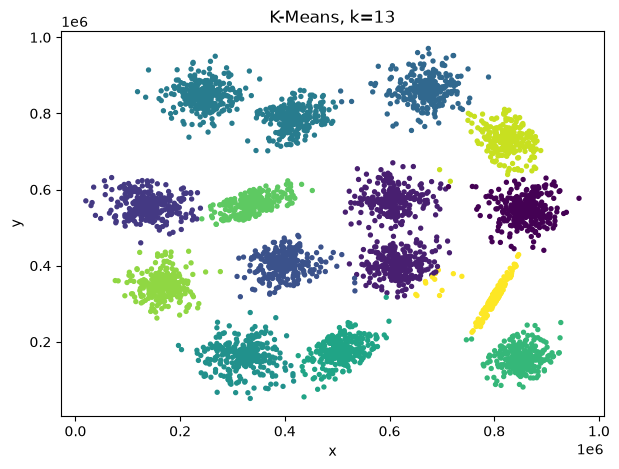

In [29]:
import matplotlib.pyplot as plt
plot_df = predictions.select('x','y','prediction').limit(10000).toPandas()
plt.figure(figsize=(7,5))
plt.scatter(plot_df['x'], plot_df['y'], c=plot_df['prediction'], s=8)
plt.xlabel('x'); plt.ylabel('y'); plt.title(f'K-Means, k={best_k}')
plt.show()

## 4B. Phân loại Spam/Ham

In [30]:
spam_rdd = sc.textFile(str(DATA_DIR / 'spam.txt')).map(lambda x: (x, 1.0))
ham_rdd  = sc.textFile(str(DATA_DIR / 'ham.txt')).map(lambda x: (x, 0.0))
text_df = spark.createDataFrame(spam_rdd.union(ham_rdd), ['text','label'])
text_df.groupBy('label').count().show()
text_df.show(5, truncate=80)

+-----+-----+
|label|count|
+-----+-----+
|  1.0|  747|
|  0.0| 4827|
+-----+-----+

+--------------------------------------------------------------------------------+-----+
|                                                                            text|label|
+--------------------------------------------------------------------------------+-----+
|                                You have 1 new message. Please call 08712400200.|  1.0|
|Urgent! Please call 09061743811 from landline. Your ABTA complimentary 4* Ten...|  1.0|
|Dear 0776xxxxxxx U've been invited to XCHAT. This is our final attempt to con...|  1.0|
|U 447801259231 have a secret admirer who is looking 2 make contact with U-fin...|  1.0|
|Congrats! 2 mobile 3G Videophones R yours. call 09061744553 now! videochat wi...|  1.0|
+--------------------------------------------------------------------------------+-----+
only showing top 5 rows



In [31]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Tokenizer, StopWordsRemover, HashingTF, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

train_df, test_df = text_df.randomSplit([0.8, 0.2], seed=42)

tokenizer = Tokenizer(inputCol='text', outputCol='tokens')
remover = StopWordsRemover(inputCol='tokens', outputCol='filtered')
hashing = HashingTF(inputCol='filtered', outputCol='tf', numFeatures=1<<14)
idf = IDF(inputCol='tf', outputCol='features')
lr = LogisticRegression(featuresCol='features', labelCol='label', maxIter=50)

pipeline = Pipeline(stages=[tokenizer, remover, hashing, idf, lr])
model = pipeline.fit(train_df)
pred = model.transform(test_df)
pred.select('text','label','prediction','probability').show(10, truncate=70)

+----------------------------------------------------------------------+-----+----------+------------------------------------------+
|                                                                  text|label|prediction|                               probability|
+----------------------------------------------------------------------+-----+----------+------------------------------------------+
|(Bank of Granite issues Strong-Buy) EXPLOSIVE PICK FOR OUR MEMBERS ...|  1.0|       1.0|              [3.6029881047858565E-19,1.0]|
|+123 Congratulations - in this week's competition draw u have won t...|  1.0|       1.0|               [3.109860832058732E-35,1.0]|
|-PLS STOP bootydelious (32/F) is inviting you to be her friend. Rep...|  1.0|       1.0|[1.0998002619019686E-8,0.9999999890019974]|
|                     100 dating service cal;l 09064012103 box334sk38ch|  1.0|       1.0|   [0.4796108245984659,0.5203891754015342]|
|                                                         2/2 146tf15

In [32]:
acc_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='accuracy')
f1_eval  = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='f1')
prec_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedPrecision')
rec_eval = MulticlassClassificationEvaluator(labelCol='label', predictionCol='prediction', metricName='weightedRecall')
auc_eval = BinaryClassificationEvaluator(labelCol='label', rawPredictionCol='rawPrediction', metricName='areaUnderROC')

print('Accuracy :', acc_eval.evaluate(pred))
print('Precision:', prec_eval.evaluate(pred))
print('Recall   :', rec_eval.evaluate(pred))
print('F1       :', f1_eval.evaluate(pred))
print('ROC-AUC  :', auc_eval.evaluate(pred))

Accuracy : 0.969187675070028
Precision: 0.9704379781831804
Recall   : 0.969187675070028
F1       : 0.9696667633872682
ROC-AUC  : 0.9816528925619848


**Câu hỏi:** Accuracy có luôn là metric tốt nhất cho phát hiện spam không? Khi dữ liệu mất cân bằng nên quan tâm thêm những metric nào?

### Accuracy có luôn là metric tốt nhất cho phát hiện spam không?

**Không.** Accuracy có thể gây hiểu nhầm khi dữ liệu mất cân bằng.

Ví dụ: nếu 99% email là email bình thường, mô hình dự đoán tất cả là “không spam” vẫn đạt Accuracy 99%, nhưng không phát hiện được email spam nào.

### Khi dữ liệu mất cân bằng nên quan tâm metric nào?

Quy ước **spam là lớp dương (positive)**.

| Metric | Ý nghĩa |
|---|---|
| **Precision của lớp spam** | Trong các email bị gắn nhãn spam, bao nhiêu email thực sự là spam? Precision cao giúp hạn chế đưa nhầm email bình thường vào thư rác. |
| **Recall của lớp spam** | Trong tất cả email spam thực tế, mô hình phát hiện được bao nhiêu? Recall cao giúp giảm bỏ sót spam. |
| **F1-score của lớp spam** | Trung bình điều hòa giữa Precision và Recall, phù hợp khi cần cân bằng hai mục tiêu. |
| **PR-AUC** | Đánh giá quan hệ giữa Precision và Recall qua các ngưỡng; đặc biệt hữu ích khi lớp spam chiếm tỷ lệ nhỏ. |
| **ROC-AUC** | Đánh giá khả năng phân biệt hai lớp qua các ngưỡng; nên xem cùng PR-AUC khi dữ liệu mất cân bằng. |
| **Confusion Matrix** | Cho biết số email bị phân loại đúng, email thường bị đánh nhầm và spam bị bỏ sót. |

### Nhận xét kết quả

Accuracy khoảng **96,92%** và ROC-AUC khoảng **0,982** là những kết quả tích cực. Tuy nhiên, cần xem tỷ lệ hai lớp và Precision, Recall, F1 riêng của lớp spam trước khi kết luận.

Nếu dùng Spark `MulticlassClassificationEvaluator`, cần kiểm tra Precision và Recall đang được tính theo dạng **weighted** hay riêng cho lớp spam. Chỉ số weighted có thể che khuất hiệu quả thấp ở lớp ít mẫu.

**Kết luận:** Không nên chỉ dựa vào Accuracy. Cần ưu tiên metric theo mục tiêu: tăng Recall để giảm bỏ sót spam, tăng Precision để hạn chế chặn nhầm email bình thường; đồng thời xem F1 và PR-AUC.

# BÀI 5. Bài tập bổ sung với people.csv và Movie ratings.csv

## 5.1 people.csv

In [33]:
people_path = DATA_DIR / 'people.csv'
people = spark.read.option('header', True).option('inferSchema', True).csv(str(people_path))
people.show()
people.printSchema()

+---+---------+-----------------+------+-------------------+
|_c0|person_id|             name|   sex|      date of birth|
+---+---------+-----------------+------+-------------------+
|  0|      100|   Penelope Lewis|female|1990-08-31 00:00:00|
|  1|      101|    David Anthony|  male|1971-10-14 00:00:00|
|  2|      102|        Ida Shipp|female|1962-05-24 00:00:00|
|  3|      103|     Joanna Moore|female|2017-03-10 00:00:00|
|  4|      104|   Lisandra Ortiz|female|2020-08-05 00:00:00|
|  5|      105|    David Simmons|  male|1999-12-30 00:00:00|
|  6|      106|    Edward Hudson|  male|1983-05-09 00:00:00|
|  7|      107|     Albert Jones|  male|1990-09-13 00:00:00|
|  8|      108| Leonard Cavender|  male|1958-08-08 00:00:00|
|  9|      109|   Everett Vadala|  male|2005-05-24 00:00:00|
| 10|      110| Freddie Claridge|  male|2002-05-07 00:00:00|
| 11|      111|Annabelle Rosseau|female|1989-07-13 00:00:00|
| 12|      112|    Eulah Emanuel|female|1976-01-19 00:00:00|
| 13|      113|       Sh

**Yêu cầu:** tự đặt ít nhất 3 câu hỏi phân tích phù hợp với các cột thực tế của `people.csv`.

1. **Số lượng và tỷ lệ người theo từng giới tính là bao nhiêu?**
   - Cột sử dụng: `sex`.

2. **Có bao nhiêu người thuộc mỗi nhóm tuổi: dưới 18, từ 18–35, từ 36–60 và trên 60?**
   - Cột sử dụng: `date of birth`.
   - Tính tuổi tại ngày phân tích, sau đó phân nhóm và đếm số người.

3. **Ai là người lớn tuổi nhất và nhỏ tuổi nhất trong dữ liệu?**
   - Cột sử dụng: `person_id`, `name`, `date of birth`.
   - Liệt kê tất cả người đồng tuổi nếu có cùng ngày sinh lớn nhất hoặc nhỏ nhất.

4. **Độ tuổi trung bình theo từng giới tính là bao nhiêu?**
   - Cột sử dụng: `sex`, `date of birth`.

5. **Có bao nhiêu mã người bị trùng và bao nhiêu bản ghi thiếu hoặc có ngày sinh không hợp lệ?**
   - Cột sử dụng: `person_id`, `date of birth`.
   - Kiểm tra chất lượng dữ liệu trước khi phân tích.

In [57]:
from pyspark.sql import functions as F

# Chuẩn hóa tên cột: "date of birth" -> "date_of_birth"
df_people = people.toDF(*[
    c.strip().lower().replace(" ", "_")
    for c in people.columns
])

# Chuyển ngày sinh và tính tuổi tại ngày chạy
df_people = (
    df_people
    .withColumn(
        "birth_date",
        F.to_date("date_of_birth", "yyyy-MM-dd")
    )
    .withColumn(
        "sex",
        F.when(
            F.col("sex").isNull() | (F.trim("sex") == ""),
            "Unknown"
        ).otherwise(F.upper(F.trim("sex")))
    )
    .withColumn(
        "age",
        F.when(
            F.col("birth_date") <= F.current_date(),
            F.year(F.current_date()) - F.year("birth_date")
            - F.when(
                F.date_format(F.current_date(), "MMdd")
                < F.date_format("birth_date", "MMdd"),
                1
            ).otherwise(0)
        )
    )
)

df_people.select(
    "person_id", "name", "sex", "birth_date", "age"
).show(truncate=False)


# Câu 1: Số lượng bản ghi theo giới tính
print("Câu 1: Số lượng theo giới tính")

df_people.groupBy("sex").agg(
    F.count("*").alias("record_count")
).orderBy(F.desc("record_count")).show()


# Câu 2: Số lượng bản ghi theo nhóm tuổi
print("Câu 2: Số lượng theo nhóm tuổi")

df_age_group = df_people.withColumn(
    "age_group",
    F.when(F.col("age").isNull(), "05. Unknown/Invalid")
    .when(F.col("age") < 18, "01. Under 18")
    .when(F.col("age") <= 35, "02. 18-35")
    .when(F.col("age") <= 60, "03. 36-60")
    .otherwise("04. Over 60")
)

df_age_group.groupBy("age_group").agg(
    F.count("*").alias("record_count")
).orderBy("age_group").show(truncate=False)


# Câu 3: Người lớn tuổi nhất và nhỏ tuổi nhất
print("Câu 3: Người lớn tuổi nhất và nhỏ tuổi nhất")

valid_people = df_people.filter(F.col("age").isNotNull())

birth_limits = valid_people.agg(
    F.min("birth_date").alias("earliest_birth"),
    F.max("birth_date").alias("latest_birth")
)

df_extremes = valid_people.crossJoin(birth_limits)

print("Người lớn tuổi nhất:")

df_extremes.filter(
    F.col("birth_date") == F.col("earliest_birth")
).select(
    "person_id", "name", "sex", "birth_date", "age"
).show(truncate=False)

print("Người nhỏ tuổi nhất:")

df_extremes.filter(
    F.col("birth_date") == F.col("latest_birth")
).select(
    "person_id", "name", "sex", "birth_date", "age"
).show(truncate=False)


# Câu 4: Tuổi trung bình theo giới tính
print("Câu 4: Tuổi trung bình theo giới tính")

valid_people.groupBy("sex").agg(
    F.count("*").alias("valid_age_count"),
    F.round(F.avg("age"), 2).alias("avg_age"),
    F.min("age").alias("min_age"),
    F.max("age").alias("max_age")
).orderBy("sex").show()


# Câu 5: Kiểm tra mã người bị trùng
print("Câu 5: Các mã person_id bị trùng")

duplicate_ids = (
    df_people
    .filter(
        F.col("person_id").isNotNull()
        & (F.trim(F.col("person_id").cast("string")) != "")
    )
    .groupBy("person_id")
    .agg(F.count("*").alias("record_count"))
    .filter(F.col("record_count") > 1)
)

duplicate_ids.orderBy(
    F.desc("record_count")
).show(truncate=False)

print("Số mã person_id bị trùng:", duplicate_ids.count())

+---------+-----------------+------+----------+---+
|person_id|name             |sex   |birth_date|age|
+---------+-----------------+------+----------+---+
|100      |Penelope Lewis   |FEMALE|1990-08-31|36 |
|101      |David Anthony    |MALE  |1971-10-14|55 |
|102      |Ida Shipp        |FEMALE|1962-05-24|64 |
|103      |Joanna Moore     |FEMALE|2017-03-10|9  |
|104      |Lisandra Ortiz   |FEMALE|2020-08-05|6  |
|105      |David Simmons    |MALE  |1999-12-30|26 |
|106      |Edward Hudson    |MALE  |1983-05-09|43 |
|107      |Albert Jones     |MALE  |1990-09-13|36 |
|108      |Leonard Cavender |MALE  |1958-08-08|68 |
|109      |Everett Vadala   |MALE  |2005-05-24|21 |
|110      |Freddie Claridge |MALE  |2002-05-07|24 |
|111      |Annabelle Rosseau|FEMALE|1989-07-13|37 |
|112      |Eulah Emanuel    |FEMALE|1976-01-19|50 |
|113      |Shaun Love       |MALE  |1970-05-26|56 |
|114      |Alejandro Brennan|MALE  |1980-12-22|45 |
|115      |Robert Mcreynolds|MALE  |1973-12-27|52 |
|116      |C

## 5.2 Movie ratings.csv

In [34]:
ratings_path = DATA_DIR / 'Movie ratings.csv'
ratings = spark.read.option('header', True).option('inferSchema', True).csv(str(ratings_path))
ratings.show(5, truncate=False)
ratings.printSchema()

+---+----+---+----------+
|1  |31  |2.5|1260759144|
+---+----+---+----------+
|1  |1029|3.0|1260759179|
|1  |1061|3.0|1260759182|
|1  |1129|2.0|1260759185|
|1  |1172|4.0|1260759205|
|1  |1263|2.0|1260759151|
+---+----+---+----------+
only showing top 5 rows

root
 |-- 1: integer (nullable = true)
 |-- 31: integer (nullable = true)
 |-- 2.5: double (nullable = true)
 |-- 1260759144: integer (nullable = true)



**Yêu cầu:**
- Kiểm tra schema và missing values.
- Tìm nhóm/phim/người dùng có số lượng rating lớn nhất tùy theo cấu trúc file.
- Tính rating trung bình theo một chiều dữ liệu phù hợp.
- Viết ít nhất 2 truy vấn Spark SQL.

In [60]:
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField,
    IntegerType, DoubleType, LongType
)

# ==================================================
# 1. ĐỌC LẠI FILE KHÔNG CÓ HEADER
# ==================================================

schema = StructType([
    StructField("user_id", IntegerType(), True),
    StructField("movie_id", IntegerType(), True),
    StructField("rating", DoubleType(), True),
    StructField("timestamp", LongType(), True)
])

ratings_path = DATA_DIR / "Movie ratings.csv"

ratings = (
    spark.read
    .option("header", False)
    .schema(schema)
    .csv(str(ratings_path))
)

ratings.show(5, truncate=False)
ratings.printSchema()


# ==================================================
# 2. KIỂM TRA MISSING VALUES
# ==================================================

print("Số lượng NULL theo cột:")

ratings.select([
    F.count(
        F.when(F.col(c).isNull(), 1)
    ).alias(c)
    for c in ratings.columns
]).show()

# Kiểm tra thêm NaN ở cột rating
ratings.select(
    F.count(
        F.when(F.isnan("rating"), 1)
    ).alias("nan_rating_count")
).show()

print("Thống kê điểm đánh giá:")

ratings.select("rating").describe().show()


# ==================================================
# 3. CHUẨN BỊ DỮ LIỆU HỢP LỆ
# ==================================================

ratings_clean = (
    ratings
    .dropna(subset=["user_id", "movie_id", "rating"])
    .filter(
        (~F.isnan("rating"))
        & (F.abs(F.col("rating")) < float("inf"))
    )
)

# Chưa lọc theo thang điểm vì cần xác nhận thang điểm của file.


# ==================================================
# 4. PHIM CÓ NHIỀU RATING NHẤT — DATAFRAME API
# ==================================================

print("Top 10 phim có nhiều rating nhất:")

movie_stats = ratings_clean.groupBy("movie_id").agg(
    F.count("*").alias("rating_count"),
    F.round(F.avg("rating"), 2).alias("avg_rating")
)

movie_stats.orderBy(
    F.desc("rating_count"),
    F.asc("movie_id")
).show(10)


# ==================================================
# 5. NGƯỜI DÙNG CÓ NHIỀU RATING NHẤT
# ==================================================

print("Top 10 người dùng có nhiều rating nhất:")

user_stats = ratings_clean.groupBy("user_id").agg(
    F.count("*").alias("rating_count"),
    F.round(F.avg("rating"), 2).alias("avg_rating")
)

user_stats.orderBy(
    F.desc("rating_count"),
    F.asc("user_id")
).show(10)


# ==================================================
# 6. RATING TRUNG BÌNH THEO PHIM
# ==================================================

print("Top 10 phim có rating trung bình cao nhất:")

movie_stats.orderBy(
    F.desc("avg_rating"),
    F.desc("rating_count"),
    F.asc("movie_id")
).show(10)


# ==================================================
# 7. SPARK SQL
# ==================================================

ratings_clean.createOrReplaceTempView("movie_ratings")

# SQL 1: Phim có nhiều rating nhất
print("SQL 1: Phim có nhiều rating nhất")

spark.sql("""
    SELECT
        movie_id,
        COUNT(*) AS rating_count,
        ROUND(AVG(rating), 2) AS avg_rating
    FROM movie_ratings
    GROUP BY movie_id
    ORDER BY rating_count DESC, movie_id
    LIMIT 10
""").show()


# SQL 2: Rating trung bình theo phim
print("SQL 2: Rating trung bình theo phim")

spark.sql("""
    SELECT
        movie_id,
        COUNT(*) AS rating_count,
        ROUND(AVG(rating), 2) AS avg_rating,
        MIN(rating) AS min_rating,
        MAX(rating) AS max_rating
    FROM movie_ratings
    GROUP BY movie_id
    ORDER BY avg_rating DESC, rating_count DESC, movie_id
    LIMIT 10
""").show()


# SQL 3: Người dùng có nhiều rating nhất
print("SQL 3: Người dùng có nhiều rating nhất")

spark.sql("""
    SELECT
        user_id,
        COUNT(*) AS rating_count,
        ROUND(AVG(rating), 2) AS avg_rating
    FROM movie_ratings
    GROUP BY user_id
    ORDER BY rating_count DESC, user_id
    LIMIT 10
""").show()

+-------+--------+------+----------+
|user_id|movie_id|rating|timestamp |
+-------+--------+------+----------+
|1      |31      |2.5   |1260759144|
|1      |1029    |3.0   |1260759179|
|1      |1061    |3.0   |1260759182|
|1      |1129    |2.0   |1260759185|
|1      |1172    |4.0   |1260759205|
+-------+--------+------+----------+
only showing top 5 rows

root
 |-- user_id: integer (nullable = true)
 |-- movie_id: integer (nullable = true)
 |-- rating: double (nullable = true)
 |-- timestamp: long (nullable = true)

Số lượng NULL theo cột:
+-------+--------+------+---------+
|user_id|movie_id|rating|timestamp|
+-------+--------+------+---------+
|      0|       0|     0|        0|
+-------+--------+------+---------+

+----------------+
|nan_rating_count|
+----------------+
|               0|
+----------------+

Thống kê điểm đánh giá:
+-------+------------------+
|summary|            rating|
+-------+------------------+
|  count|            100004|
|   mean| 3.543608255669773|
| stddev

# BÀI MỞ RỘNG

Chọn dataset tối thiểu **100.000 dòng**, thực hiện:
1. Data Understanding.
2. Data Cleaning.
3. Ít nhất 6 thao tác DataFrame.
4. Ít nhất 5 truy vấn Spark SQL.
5. Ít nhất 5 câu hỏi phân tích.
6. Một mô hình ML bằng `pyspark.ml`.
7. Kết luận và hạn chế.

# 1. Chọn dataset và xác định mục tiêu
Dataset: NYC Yellow Taxi Trip Records – tháng 01/2024, do NYC Taxi & Limousine Commission công bố dưới dạng Parquet. Dữ liệu có thông tin thời gian, địa điểm, quãng đường, tiền cước và phương thức thanh toán.
Mục tiêu:
- Phân tích nhu cầu di chuyển theo thời gian và địa điểm.
- Phân tích quãng đường, thời lượng và tiền cước.
- Xây dựng mô hình hồi quy dự đoán fare_amount.

In [35]:
#Khởi tạo Spark và đọc dữ liệu:
from pathlib import Path
from urllib.request import urlretrieve

from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .appName("NYC_Taxi_Analysis")
    .master("local[*]")
    .config("spark.sql.session.timeZone", "America/New_York")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

url = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "trip-data/yellow_tripdata_2024-01.parquet"
)

file_path = Path("yellow_tripdata_2024-01.parquet")

if not file_path.exists():
    urlretrieve(url, str(file_path))

df_raw = spark.read.parquet(str(file_path))

n_raw = df_raw.count()

print("Spark version:", spark.version)
print(f"Số dòng ban đầu: {n_raw:,}")
print("Số cột:", len(df_raw.columns))

assert n_raw >= 100_000, "Dataset chưa đáp ứng yêu cầu 100.000 dòng."

Spark version: 3.5.3
Số dòng ban đầu: 2,964,624
Số cột: 19


# 2. Data Understanding

In [36]:
# Cấu trúc dữ liệu
df_raw.printSchema()

# Xem 5 dòng
df_raw.show(5, truncate=False)

# Thống kê các biến số chính
numeric_cols = [
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "total_amount"
]

df_raw.select(numeric_cols).describe().show()

# Số lượng giá trị NULL theo cột
df_raw.select([
    F.sum(F.col(c).isNull().cast("long")).alias(c)
    for c in df_raw.columns
]).show(vertical=True)

# Khoảng thời gian ghi nhận
df_raw.select(
    F.min("tpep_pickup_datetime").alias("min_pickup"),
    F.max("tpep_pickup_datetime").alias("max_pickup")
).show()

# Phân bố phương thức thanh toán
df_raw.groupBy("payment_type").count().orderBy(
    F.desc("count")
).show()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------

# 3. Data cleaning

In [38]:
from pyspark.sql import functions as F

spark.conf.set("spark.sql.session.timeZone", "America/New_York")

df_duration = df_month.withColumn(
    "duration_min",
    (
        F.col("tpep_dropoff_datetime")
         .cast("timestamp_ltz")
         .cast("long")
        -
        F.col("tpep_pickup_datetime")
         .cast("timestamp_ltz")
         .cast("long")
    ) / 60.0
)

# Kiểm tra kết quả
df_duration.select(
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "duration_min"
).show(10, truncate=False)

+--------------------+---------------------+------------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|duration_min      |
+--------------------+---------------------+------------------+
|2024-01-01 00:57:55 |2024-01-01 01:17:43  |19.8              |
|2024-01-01 00:03:00 |2024-01-01 00:09:36  |6.6               |
|2024-01-01 00:17:06 |2024-01-01 00:35:01  |17.916666666666668|
|2024-01-01 00:36:38 |2024-01-01 00:44:56  |8.3               |
|2024-01-01 00:46:51 |2024-01-01 00:52:57  |6.1               |
|2024-01-01 00:54:08 |2024-01-01 01:26:31  |32.38333333333333 |
|2024-01-01 00:49:44 |2024-01-01 01:15:47  |26.05             |
|2024-01-01 00:30:40 |2024-01-01 00:58:40  |28.0              |
|2024-01-01 00:26:01 |2024-01-01 00:54:12  |28.183333333333334|
|2024-01-01 00:28:08 |2024-01-01 00:29:16  |1.1333333333333333|
+--------------------+---------------------+------------------+
only showing top 10 rows



# 4. Ít nhất 6 thao tác DataFrame

In [45]:
from pyspark.sql import functions as F

spark.conf.set("spark.sql.session.timeZone", "America/New_York")

# 1. Tính thời lượng, xử lý kiểu TIMESTAMP_NTZ
df_duration = df_month.withColumn(
    "duration_min",
    (
        F.col("tpep_dropoff_datetime").cast("timestamp_ltz").cast("long")
        - F.col("tpep_pickup_datetime").cast("timestamp_ltz").cast("long")
    ) / 60.0
)

# 2. Tạo DataFrame đã làm sạch
df_clean = df_duration.filter(
    (F.col("trip_distance") > 0)
    & (F.col("trip_distance") < float("inf"))
    & (~F.isnan("trip_distance"))
    & (F.col("fare_amount") > 0)
    & (F.col("fare_amount") < float("inf"))
    & (~F.isnan("fare_amount"))
    & (F.col("duration_min") > 0)
).cache()

# 3. Kiểm tra
print(f"Số dòng sau làm sạch: {df_clean.count():,}")

df_clean.select(
    "trip_distance",
    "duration_min",
    "fare_amount"
).show(5)

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Kiểm tra các cột cần sử dụng
required_cols = [
    "tpep_pickup_datetime",
    "trip_distance",
    "duration_min",
    "fare_amount",
    "PULocationID",
    "payment_type"
]

missing_cols = [c for c in required_cols if c not in df_clean.columns]

if missing_cols:
    raise ValueError(f"Thiếu các cột: {missing_cols}")

# 1. SELECT: chọn cột
print("1. Chọn cột")

df_clean.select(
    "trip_distance",
    "duration_min",
    "fare_amount"
).show(5)


# 2. FILTER: lọc chuyến dài trên 10 mile
print("2. Chuyến có quãng đường trên 10 mile")

df_clean.filter(
    F.col("trip_distance") > 10
).select(
    "trip_distance",
    "duration_min",
    "fare_amount"
).show(5)


# 3. WITHCOLUMN: tạo biến mới
# dayofweek: Chủ nhật = 1, Thứ hai = 2, ..., Thứ bảy = 7
df_analysis = (
    df_clean
    .withColumn(
        "pickup_date",
        F.to_date("tpep_pickup_datetime")
    )
    .withColumn(
        "pickup_hour",
        F.hour("tpep_pickup_datetime")
    )
    .withColumn(
        "day_of_week",
        F.dayofweek("tpep_pickup_datetime")
    )
    .withColumn(
        "day_type",
        F.when(
            F.col("day_of_week").isin(1, 7),
            "Weekend"
        ).otherwise("Weekday")
    )
    .withColumn(
        "distance_group",
        F.when(
            F.col("trip_distance") <= 2,
            "01. <=2 miles"
        )
        .when(
            F.col("trip_distance") <= 5,
            "02. >2-5 miles"
        )
        .when(
            F.col("trip_distance") <= 10,
            "03. >5-10 miles"
        )
        .otherwise("04. >10 miles")
    )
).cache()

print("3. Các biến mới")

df_analysis.select(
    "pickup_date",
    "pickup_hour",
    "day_of_week",
    "day_type",
    "trip_distance",
    "distance_group"
).show(5, truncate=False)


# 4. GROUPBY + AGG: thống kê theo giờ
hourly_stats = df_analysis.groupBy("pickup_hour").agg(
    F.count("*").alias("trip_count"),
    F.round(F.avg("fare_amount"), 2).alias("avg_fare"),
    F.round(F.avg("duration_min"), 2).alias("avg_duration_min")
)

print("4. Thống kê theo giờ")

hourly_stats.orderBy("pickup_hour").show(24)


# 5. ORDERBY: sắp xếp giờ đông khách nhất
print("5. Giờ có nhiều chuyến nhất")

hourly_stats.orderBy(
    F.desc("trip_count"),
    F.asc("pickup_hour")
).show(24)


# 6. DISTINCT: lấy danh sách vùng đón khách
print("6. Các mã vùng đón khách")

df_analysis.select(
    "PULocationID"
).distinct().orderBy("PULocationID").show(10)


# 7. JOIN: ghép tổng số chuyến theo vùng
zone_counts = (
    df_analysis
    .filter(F.col("PULocationID").isNotNull())
    .groupBy("PULocationID")
    .agg(
        F.count("*").alias("zone_trip_count")
    )
)

df_with_zone = df_analysis.join(
    zone_counts,
    on="PULocationID",
    how="left"
)

print("7. Dữ liệu sau khi join")

df_with_zone.select(
    "PULocationID",
    "trip_distance",
    "fare_amount",
    "zone_trip_count"
).show(5)


# 8. WINDOW: xếp hạng vùng theo số chuyến
# Window chạy trên bảng đã tổng hợp theo vùng.
ranking_window = Window.orderBy(
    F.desc("zone_trip_count")
)

zone_ranked = zone_counts.withColumn(
    "zone_rank",
    F.dense_rank().over(ranking_window)
)

print("8. Xếp hạng vùng đón khách")

zone_ranked.orderBy(
    "zone_rank",
    "PULocationID"
).show(10)

Số dòng sau làm sạch: 2,869,585
+-------------+------------------+-----------+
|trip_distance|      duration_min|fare_amount|
+-------------+------------------+-----------+
|         1.72|              19.8|       17.7|
|          1.8|               6.6|       10.0|
|          4.7|17.916666666666668|       23.3|
|          1.4|               8.3|       10.0|
|          0.8|               6.1|        7.9|
+-------------+------------------+-----------+
only showing top 5 rows

1. Chọn cột
+-------------+------------------+-----------+
|trip_distance|      duration_min|fare_amount|
+-------------+------------------+-----------+
|         1.72|              19.8|       17.7|
|          1.8|               6.6|       10.0|
|          4.7|17.916666666666668|       23.3|
|          1.4|               8.3|       10.0|
|          0.8|               6.1|        7.9|
+-------------+------------------+-----------+
only showing top 5 rows

2. Chuyến có quãng đường trên 10 mile
+-------------+-------

# 5. Ít nhất 5 truy vấn Spark SQL và 5 câu hỏi phân tích

In [46]:
df_analysis.createOrReplaceTempView("taxi")

Câu 1. Khung giờ có nhiều chuyến nhất

In [47]:
q1 = spark.sql("""
    SELECT
        pickup_hour,
        COUNT(*) AS trip_count,
        ROUND(AVG(fare_amount), 2) AS avg_fare,
        ROUND(AVG(duration_min), 2) AS avg_duration_min
    FROM taxi
    GROUP BY pickup_hour
    ORDER BY trip_count DESC, pickup_hour
""")

q1.show(24)

+-----------+----------+--------+----------------+
|pickup_hour|trip_count|avg_fare|avg_duration_min|
+-----------+----------+--------+----------------+
|         18|    206258|   17.02|           15.02|
|         17|    200283|   18.13|           16.78|
|         16|    184948|   19.46|           17.76|
|         15|    183973|   19.12|            17.6|
|         19|    178788|   17.64|            14.5|
|         14|    178003|   19.28|           17.35|
|         13|    165327|   18.42|           16.45|
|         12|    159886|   17.81|            15.7|
|         21|    155889|   18.31|           14.21|
|         20|    155539|   18.05|           14.18|
|         11|    146725|   17.63|            15.8|
|         22|    138228|   19.11|           14.64|
|         10|    135404|   18.08|           15.97|
|          9|    125596|   17.95|           15.81|
|          8|    113481|   17.84|           15.73|
|         23|    104613|   20.25|           15.04|
|          7|     80855|   18.7

Câu 2. Top 10 vùng đón khách có nhiều chuyến nhất

In [48]:
q2 = spark.sql("""
    WITH zone_summary AS (
        SELECT
            PULocationID,
            COUNT(*) AS trip_count,
            AVG(trip_distance) AS avg_distance,
            AVG(fare_amount) AS avg_fare
        FROM taxi
        WHERE PULocationID IS NOT NULL
        GROUP BY PULocationID
    )
    SELECT
        PULocationID,
        trip_count,
        ROUND(
            100.0 * trip_count / SUM(trip_count) OVER (),
            2
        ) AS percentage,
        ROUND(avg_distance, 2) AS avg_distance_miles,
        ROUND(avg_fare, 2) AS avg_fare
    FROM zone_summary
    ORDER BY trip_count DESC, PULocationID
    LIMIT 10
""")

q2.show()

+------------+----------+----------+------------------+--------+
|PULocationID|trip_count|percentage|avg_distance_miles|avg_fare|
+------------+----------+----------+------------------+--------+
|         161|    140140|      4.88|               2.6|    15.5|
|         237|    140117|      4.88|              1.72|   12.38|
|         132|    138446|      4.82|             15.94|   62.87|
|         236|    133961|      4.67|              1.87|   12.86|
|         162|    104342|      3.64|              2.26|   15.07|
|         230|    102958|      3.59|              2.97|    17.9|
|         186|    102151|      3.56|               2.3|   16.09|
|         142|    101794|      3.55|              2.12|   13.62|
|         138|     87693|      3.06|              9.71|   42.35|
|         239|     86466|      3.01|              2.29|   13.61|
+------------+----------+----------+------------------+--------+



Câu 3. Ngày thường và cuối tuần khác nhau thế nào?

In [49]:
q3 = spark.sql("""
    WITH daily_summary AS (
        SELECT
            pickup_date,
            day_type,
            COUNT(*) AS trip_count,
            SUM(fare_amount) AS fare_sum
        FROM taxi
        GROUP BY pickup_date, day_type
    )
    SELECT
        day_type,
        COUNT(*) AS number_of_days,
        ROUND(AVG(trip_count), 2) AS avg_daily_trips,
        ROUND(AVG(fare_sum), 2) AS avg_daily_fare_sum,
        ROUND(
            SUM(fare_sum) / SUM(trip_count),
            2
        ) AS avg_fare_per_trip
    FROM daily_summary
    GROUP BY day_type
    ORDER BY day_type
""")

q3.show()

+--------+--------------+---------------+------------------+-----------------+
|day_type|number_of_days|avg_daily_trips|avg_daily_fare_sum|avg_fare_per_trip|
+--------+--------------+---------------+------------------+-----------------+
| Weekday|            23|       92856.22|        1736724.24|             18.7|
| Weekend|             8|        91736.5|        1642365.03|             17.9|
+--------+--------------+---------------+------------------+-----------------+



Câu 4. Tiền cước và thời lượng khác nhau thế nào theo nhóm quãng đường?

In [50]:
q4 = spark.sql("""
    SELECT
        distance_group,
        COUNT(*) AS trip_count,
        ROUND(AVG(trip_distance), 2) AS avg_distance_miles,
        ROUND(AVG(duration_min), 2) AS avg_duration_min,
        ROUND(AVG(fare_amount), 2) AS avg_fare
    FROM taxi
    GROUP BY distance_group
    ORDER BY distance_group
""")

q4.show(truncate=False)

+---------------+----------+------------------+----------------+--------+
|distance_group |trip_count|avg_distance_miles|avg_duration_min|avg_fare|
+---------------+----------+------------------+----------------+--------+
|01. <=2 miles  |1663472   |1.14              |9.41            |9.97    |
|02. >2-5 miles |750493    |3.0               |18.62           |18.76   |
|03. >5-10 miles|230584    |7.28              |26.65           |34.04   |
|04. >10 miles  |225036    |21.71             |41.96           |64.75   |
+---------------+----------+------------------+----------------+--------+



Câu 5. Phương thức thanh toán nào phổ biến nhất

In [51]:
q5 = spark.sql("""
    WITH payment_summary AS (
        SELECT
            payment_type,
            COUNT(*) AS trip_count
        FROM taxi
        GROUP BY payment_type
    )
    SELECT
        payment_type,
        trip_count,
        ROUND(
            100.0 * trip_count / SUM(trip_count) OVER (),
            2
        ) AS percentage
    FROM payment_summary
    ORDER BY trip_count DESC
""")

q5.show()

+------------+----------+----------+
|payment_type|trip_count|percentage|
+------------+----------+----------+
|           1|   2298339|     80.09|
|           2|    422731|     14.73|
|           0|    115195|      4.01|
|           4|     22759|      0.79|
|           3|     10561|      0.37|
+------------+----------+----------+



Câu 6. Quãng đường và thời lượng có tương quan với tiền cước không?

In [52]:
q6 = spark.sql("""
    SELECT
        ROUND(
            CORR(trip_distance, fare_amount), 4
        ) AS corr_distance_fare,
        ROUND(
            CORR(duration_min, fare_amount), 4
        ) AS corr_duration_fare
    FROM taxi
""")

q6.show()

+------------------+------------------+
|corr_distance_fare|corr_duration_fare|
+------------------+------------------+
|            0.0183|            0.2808|
+------------------+------------------+



# 5. Mô hình ML bằng pyspark.ml

Dùng Linear Regression để dự đoán tiền cước từ quãng đường và thời lượng thực tế. Đây là mô hình ước lượng cho chuyến đã hoàn thành.

In [53]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

# 1. Chuẩn bị dữ liệu
df_ml = df_analysis.select(
    "pickup_date",
    F.col("trip_distance").cast("double").alias("trip_distance"),
    F.col("duration_min").cast("double").alias("duration_min"),
    F.col("fare_amount").cast("double").alias("label")
).dropna(
    subset=[
        "pickup_date",
        "trip_distance",
        "duration_min",
        "label"
    ]
)

# 2. Chia train/test theo ngày.
# Dùng kiểu DATE để tránh vấn đề TIMESTAMP_NTZ.
cutoff_date = F.lit("2024-01-25").cast("date")

train = df_ml.filter(
    F.col("pickup_date") < cutoff_date
).cache()

test = df_ml.filter(
    F.col("pickup_date") >= cutoff_date
).cache()

n_train = train.count()
n_test = test.count()

print(f"Số dòng train: {n_train:,}")
print(f"Số dòng test: {n_test:,}")

if n_train == 0 or n_test < 2:
    raise ValueError(
        "Không đủ dữ liệu train/test. "
        "Kiểm tra lại khoảng thời gian của dataset."
    )

# 3. Chuyển các biến đầu vào thành vector
feature_cols = [
    "trip_distance",
    "duration_min"
]

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features",
    handleInvalid="error"
)

# 4. Khai báo mô hình
lr = LinearRegression(
    featuresCol="features",
    labelCol="label",
    predictionCol="prediction",
    maxIter=100,
    regParam=0.1,
    elasticNetParam=0.0
)

pipeline = Pipeline(
    stages=[assembler, lr]
)

# 5. Huấn luyện trên train
model = pipeline.fit(train)

# 6. Dự đoán trên test
predictions = model.transform(test).cache()

predictions.select(
    "trip_distance",
    "duration_min",
    F.round("label", 2).alias("actual_fare"),
    F.round("prediction", 2).alias("predicted_fare")
).show(10)

# 7. Baseline: dự đoán bằng tiền cước trung bình của train
train_mean = train.agg(
    F.avg("label").alias("mean_fare")
).first()["mean_fare"]

baseline_predictions = test.withColumn(
    "prediction",
    F.lit(float(train_mean))
)

# 8. Đánh giá mô hình và baseline
evaluation_results = []
metrics_by_model = {}

for model_name, prediction_df in [
    ("Baseline", baseline_predictions),
    ("Linear Regression", predictions)
]:
    model_metrics = {}

    for metric_name in ["mae", "rmse", "r2"]:
        evaluator = RegressionEvaluator(
            labelCol="label",
            predictionCol="prediction",
            metricName=metric_name
        )

        model_metrics[metric_name] = float(
            evaluator.evaluate(prediction_df)
        )

    metrics_by_model[model_name] = model_metrics

    evaluation_results.append((
        model_name,
        model_metrics["mae"],
        model_metrics["rmse"],
        model_metrics["r2"]
    ))

df_metrics = spark.createDataFrame(
    evaluation_results,
    schema=["model", "MAE_USD", "RMSE_USD", "R2"]
)

df_metrics.select(
    "model",
    F.round("MAE_USD", 4).alias("MAE_USD"),
    F.round("RMSE_USD", 4).alias("RMSE_USD"),
    F.round("R2", 4).alias("R2")
).show(truncate=False)

# 9. Hệ số mô hình
lr_model = model.stages[-1]

print(f"Intercept: {lr_model.intercept:.4f}")

for feature_name, coefficient in zip(
    feature_cols,
    lr_model.coefficients
):
    print(f"{feature_name}: {coefficient:.4f}")

# 10. Các chuyến có sai số lớn nhất
print("10 chuyến có sai số tuyệt đối lớn nhất:")

(
    predictions
    .withColumn(
        "absolute_error",
        F.abs(F.col("label") - F.col("prediction"))
    )
    .select(
        "trip_distance",
        "duration_min",
        "label",
        "prediction",
        "absolute_error"
    )
    .orderBy(F.desc("absolute_error"))
    .show(10, truncate=False)
)

Số dòng train: 2,183,516
Số dòng test: 686,069
+-------------+------------------+-----------+--------------+
|trip_distance|      duration_min|actual_fare|predicted_fare|
+-------------+------------------+-----------+--------------+
|         13.7|             29.95|       52.7|         20.61|
|          2.4|              10.8|       12.8|         17.95|
|          1.0| 7.666666666666667|        9.3|         17.52|
|         2.78| 6.133333333333334|       12.8|         17.32|
|         2.61|14.033333333333333|       16.3|          18.4|
|         2.58|              9.85|       13.5|         17.83|
|         1.04|              6.35|        8.6|         17.34|
|          0.5|               2.7|        5.1|         16.84|
|          0.9| 5.183333333333334|        7.2|         17.18|
|          1.4|10.966666666666667|       10.0|         17.97|
+-------------+------------------+-----------+--------------+
only showing top 10 rows

+-----------------+-------+--------+-------+
|model        

# 7. Tổng hợp kết quả và hạn chế

In [54]:
# Quy mô dữ liệu
n_clean_final = df_clean.count()

print("KẾT QUẢ PHÂN TÍCH")
print(f"- Số dòng sau làm sạch: {n_clean_final:,}")

# Giờ đông khách nhất
top_hour = q1.first()

print(
    f"- Giờ có nhiều chuyến nhất: {top_hour['pickup_hour']} giờ, "
    f"với {top_hour['trip_count']:,} chuyến."
)

# Vùng đón khách nhiều nhất
top_zone = q2.first()

print(
    f"- Vùng đón khách nhiều nhất: {top_zone['PULocationID']}, "
    f"với {top_zone['trip_count']:,} chuyến, "
    f"chiếm {top_zone['percentage']}% số chuyến có mã vùng."
)

# Ngày thường và cuối tuần
for row in q3.collect():
    print(
        f"- {row['day_type']}: "
        f"trung bình {row['avg_daily_trips']:,.2f} chuyến/ngày; "
        f"tiền cước trung bình {row['avg_fare_per_trip']} USD/chuyến."
    )

# Nhóm khoảng cách có cước trung bình cao nhất
top_distance = q4.orderBy(
    F.desc("avg_fare")
).first()

print(
    f"- Nhóm có tiền cước trung bình cao nhất: "
    f"{top_distance['distance_group']}, "
    f"đạt {top_distance['avg_fare']} USD/chuyến."
)

# Kết quả mô hình
lr_metrics = metrics_by_model["Linear Regression"]
baseline_metrics = metrics_by_model["Baseline"]

print(
    f"- Linear Regression: "
    f"MAE = {lr_metrics['mae']:.2f} USD; "
    f"RMSE = {lr_metrics['rmse']:.2f} USD; "
    f"R² = {lr_metrics['r2']:.4f}."
)

for metric in ["mae", "rmse"]:
    baseline_value = baseline_metrics[metric]
    model_value = lr_metrics[metric]

    if baseline_value > 0:
        improvement = (
            (baseline_value - model_value)
            / baseline_value * 100
        )

        print(
            f"- Mức giảm {metric.upper()} so với baseline: "
            f"{improvement:.2f}% "
            "(giá trị âm nghĩa là mô hình kém hơn baseline)."
        )

KẾT QUẢ PHÂN TÍCH
- Số dòng sau làm sạch: 2,869,585
- Giờ có nhiều chuyến nhất: 18 giờ, với 206,258 chuyến.
- Vùng đón khách nhiều nhất: 161, với 140,140 chuyến, chiếm 4.88% số chuyến có mã vùng.
- Weekday: trung bình 92,856.22 chuyến/ngày; tiền cước trung bình 18.7 USD/chuyến.
- Weekend: trung bình 91,736.50 chuyến/ngày; tiền cước trung bình 17.9 USD/chuyến.
- Nhóm có tiền cước trung bình cao nhất: 04. >10 miles, đạt 64.75 USD/chuyến.
- Linear Regression: MAE = 9.63 USD; RMSE = 15.66 USD; R² = 0.0770.
- Mức giảm MAE so với baseline: 9.27% (giá trị âm nghĩa là mô hình kém hơn baseline).
- Mức giảm RMSE so với baseline: 3.98% (giá trị âm nghĩa là mô hình kém hơn baseline).


Hạn chế:
- Dữ liệu chỉ bao gồm tháng 01/2024, chưa phản ánh tính mùa vụ.
- Kết quả phân tích áp dụng cho những chuyến được giữ lại sau làm sạch.
- Các ngoại lệ còn lại có thể ảnh hưởng đến trung bình, tương quan và mô hình.
- Mô hình mới sử dụng hai biến, chưa xét vùng đón/trả, loại giá cước, giao thông và thời tiết.
- Quãng đường và thời lượng thực tế chỉ có sau chuyến đi, nên mô hình chưa dùng để báo giá trước chuyến.
- Cần kiểm tra thêm trên các tháng khác để đánh giá khả năng khái quát.

## Checklist nộp bài

- [x] Notebook chạy từ đầu đến cuối.
- [x] Không dùng `collect()`/`toPandas()` cho toàn bộ Big Data.
- [x] Có giải thích kết quả, không chỉ có code.
- [x] Có Spark SQL và DataFrame API.
- [x] Có ít nhất một mô hình ML.
- [x] Có phần kết luận.